# Vault Ledger: data landscape and how to combine it

What this notebook answers:
1. **What our model is** and how it scores today.
2. **What data we downloaded** (`data/external/`, about 9 GB) and what each source can be used for.
3. **Which sources fit our input format** (vendor + description -> account).
4. **How far the public data is from ours** (length, language, vocabulary).
5. **Mapping their categories onto our 7 accounts.**
6. **Experiments**: does adding public data help the TF-IDF fusion model? Which manipulation works?
7. **Decision guide.**

Results on synthetic data are not real-world accuracy.

In [1]:
import sys, json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd()))
import data_sources as ds
REPO = ds.REPO
# reference palette (categorical, fixed order) + text/grid tokens
PAL = ['#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4','#008300','#6250d6','#e34948']
ACC_COLOR = dict(zip(ds.ACCOUNTS, PAL))
ACC_COLOR.update({'EXCLUDE':'#c3c2b7','UNMAPPED':'#898781'})
plt.rcParams.update({'figure.facecolor':'#fcfcfb','axes.facecolor':'#fcfcfb','axes.edgecolor':'#c3c2b7',
    'axes.labelcolor':'#52514e','xtick.color':'#52514e','ytick.color':'#52514e','axes.grid':True,
    'grid.color':'#e1e0d9','grid.linewidth':0.6,'axes.spines.top':False,'axes.spines.right':False,
    'font.size':10,'axes.titlesize':12,'axes.titleweight':'bold','figure.dpi':110})
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)

## 1. Our model

**Pipeline:** document -> extraction (OCR / PDF / e-invoice -> vendor, description, date, amount, paid) -> **classifier cascade** -> confidence gate (low confidence goes to the review queue) -> deterministic debit/credit rules.

**The cascade** (`src/vault_ledger/classifier/cascade.py`), first confident answer wins:

| Order | Model | Input | Notes |
|---|---|---|---|
| 0 | Personal DragoNet | vendor, description, amount, paid, date | retrained per user on their corrections (x30 weight) + their own accounts |
| 1 | DragoNet `pretrained-top2` | same | multilingual-e5-small encoders, top 2 layers fine-tuned, macro+micro heads |
| 2 | DragoNet `pretrained-vatpaid` | same + VAT/paid features | frozen encoder |
| 3 | TF-IDF fusion | vendor, description | two separate TF-IDF vectorizers, concatenated, logistic regression |

**Label space:** 7 expense accounts (Cash/Bank and Accounts Payable are only used by the rules). The key design rule: **vendor and description are encoded separately, then fused**. Never one blended text field.

**Training data today:** 10,000 synthetic rows (`data/synthetic/generated/`), Dutch and English, vendor-disjoint train/val/test.

In [2]:
runs = []
for d in sorted((REPO/'vaultledger-ml'/'runs').glob('*')):
    for split, fn in (('validation','metrics.json'),('test','test_metrics.json')):
        p = d/fn
        if not p.exists(): continue
        m = json.loads(p.read_text())
        v = m.get('validation', m) if split=='validation' else m
        if 'micro_level' in v:
            runs.append({'run':d.name,'split':split,'accuracy':v['micro_level']['accuracy'],'macro_f1':v['micro_level']['macro_f1']})
runs = pd.DataFrame(runs); runs

,run,split,accuracy,macro_f1
0,pretrained-synth,validation,0.941327,0.884733
1,smoke,validation,0.537671,0.341713
2,synth-crew-2026-pretrained-top2,validation,0.698413,0.625365
3,synth-crew-2026-pretrained-top2,test,0.647253,0.586675
4,synth-crew-2026-pretrained-vatpaid,validation,0.641534,0.559236
5,synth-crew-2026-pretrained-vatpaid,test,0.664461,0.587270
6,synth-crew-4321-pretrained,validation,0.641196,0.616926
7,synth-crew-4321-pretrained,test,0.645485,0.611576
8,synth-crew-4321-pretrained-top2,validation,0.719269,0.687437
9,synth-crew-4321-pretrained-top2,test,0.762542,0.706840


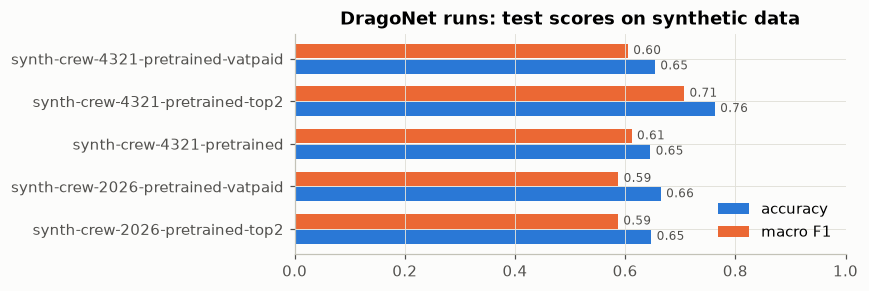

In [3]:
t = runs[runs.split=='test'].set_index('run')
fig, ax = plt.subplots(figsize=(8, 0.5+0.45*len(t)))
y = np.arange(len(t))
ax.barh(y-0.18, t.accuracy, 0.34, color=PAL[0], label='accuracy')
ax.barh(y+0.18, t.macro_f1, 0.34, color=PAL[1], label='macro F1')
for i,(a,f) in enumerate(zip(t.accuracy,t.macro_f1)):
    ax.text(a+0.01,i-0.18,f'{a:.2f}',va='center',fontsize=8,color='#52514e'); ax.text(f+0.01,i+0.18,f'{f:.2f}',va='center',fontsize=8,color='#52514e')
ax.set_yticks(y, t.index); ax.set_xlim(0,1); ax.legend(loc='lower right', frameon=False)
ax.set_title('DragoNet runs: test scores on synthetic data'); plt.tight_layout(); plt.show()

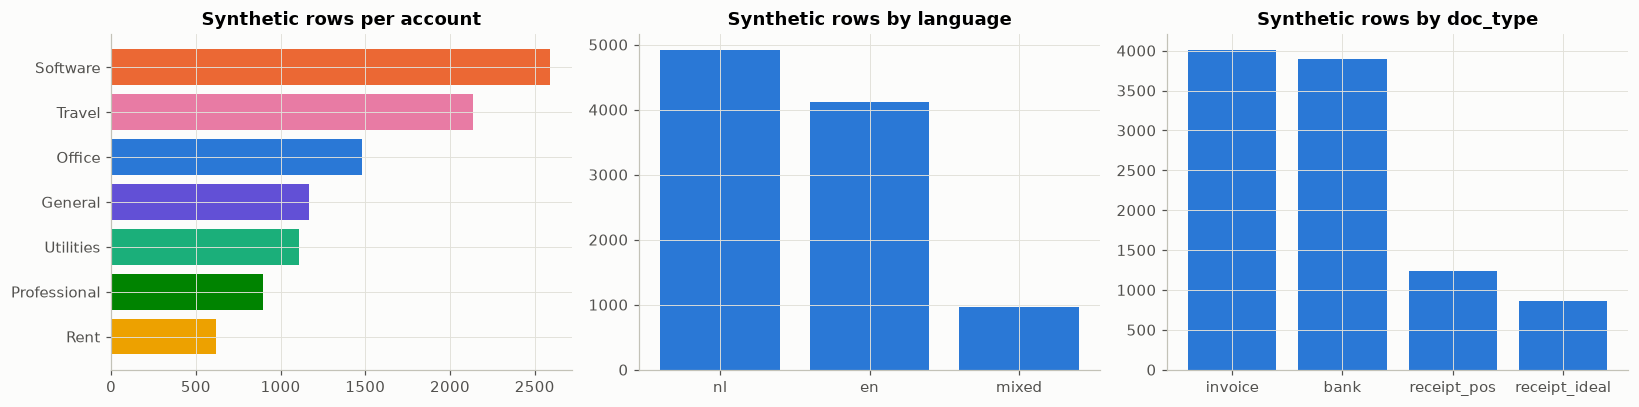

In [4]:
syn = ds._synthetic(); meta = pd.read_csv(ds.SYNTH/'metadata_2026.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
vc = syn.label_raw.value_counts()
axes[0].barh([ds.SHORT[a] for a in vc.index], vc.values, color=[ACC_COLOR[a] for a in vc.index]); axes[0].invert_yaxis()
axes[0].set_title('Synthetic rows per account')
for col, ax in zip(['language','doc_type'], axes[1:]):
    v = meta[col].value_counts(); ax.bar(v.index.astype(str), v.values, color=PAL[0]); ax.set_title(f'Synthetic rows by {col}')
plt.tight_layout(); plt.show()

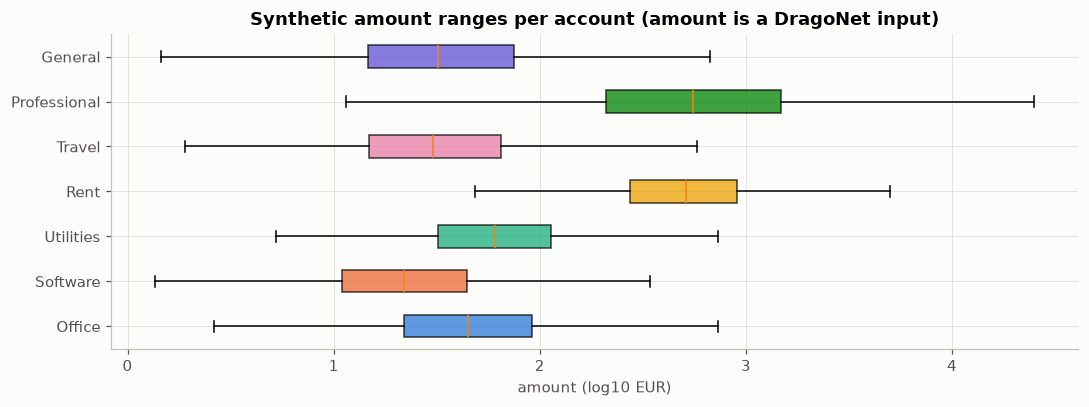

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
data = [np.log10(syn.loc[syn.label_raw==a,'amount'].clip(lower=0.5)) for a in ds.ACCOUNTS]
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.5, showfliers=False)
for p,a in zip(bp['boxes'], ds.ACCOUNTS): p.set_facecolor(ACC_COLOR[a]); p.set_alpha(0.75)
ax.set_yticks(range(1,8), [ds.SHORT[a] for a in ds.ACCOUNTS]); ax.set_xlabel('amount (log10 EUR)')
ax.set_title('Synthetic amount ranges per account (amount is a DragoNet input)'); plt.tight_layout(); plt.show()

## 2. What we downloaded

                  datasets    gb  files
group                                  
documents               16  4.48  59083
huggingface             36  2.54   4178
kaggle                  48  0.93   3552
ledger_standards        17  1.38   1729
transactions            25  0.49   1601
total GB: 9.82


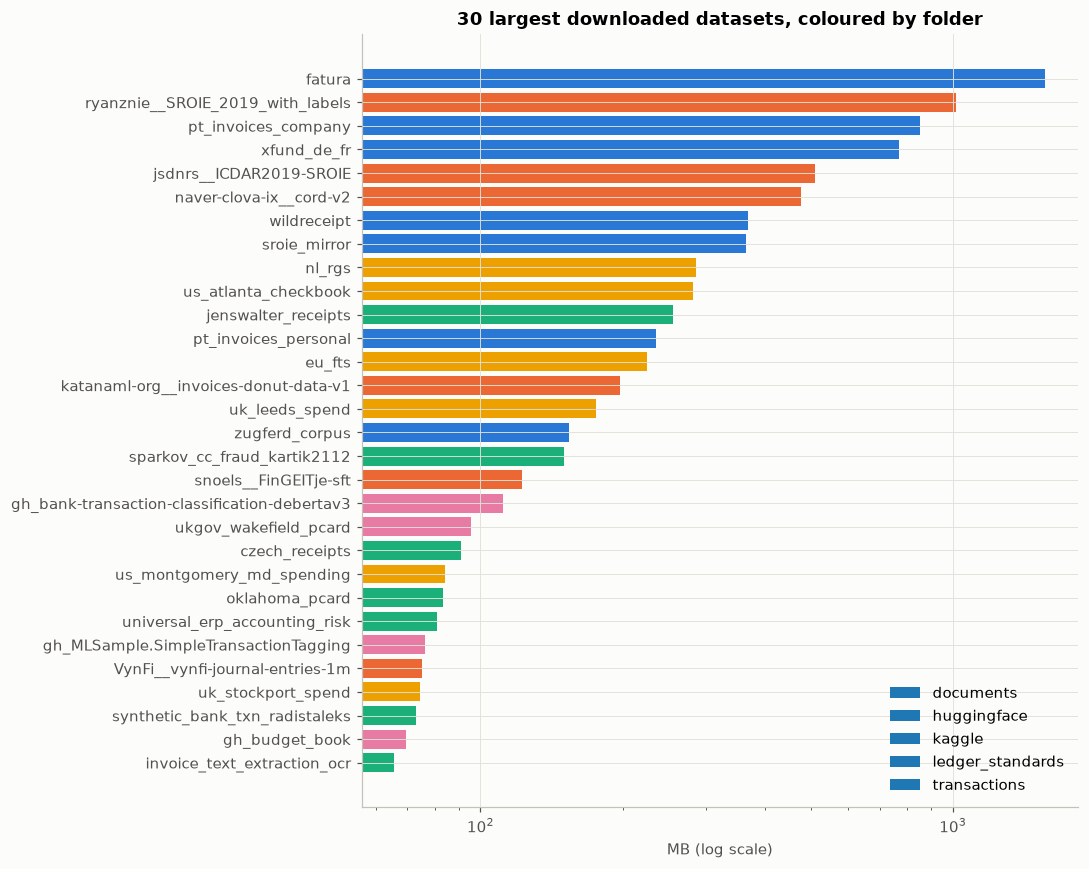

In [6]:
inv = ds.inventory()
g = inv.groupby('group').agg(datasets=('dataset','count'), gb=('mb', lambda s: s.sum()/1000), files=('files','sum'))
print(g.round(2)); print('total GB:', round(inv.mb.sum()/1000, 2))
top = inv.sort_values('mb', ascending=False).head(30)
gc = {g:PAL[i] for i,g in enumerate(sorted(inv.group.unique()))}
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top.dataset, top.mb, color=[gc[x] for x in top.group]); ax.invert_yaxis(); ax.set_xscale('log')
ax.set_xlabel('MB (log scale)'); ax.set_title('30 largest downloaded datasets, coloured by folder')
for g_,c in gc.items(): ax.barh([], [], color=c, label=g_)
ax.legend(frameon=False, loc='lower right'); plt.tight_layout(); plt.show()

## 3. Harmonize: every labeled source -> one table

`data_sources.py` reads each source and maps its columns to **vendor, description, amount, label_raw**. Then `map_to_account()` maps label_raw to one of our 7 accounts, or **EXCLUDE** (sales, transfers, payroll, tax payments...) or **UNMAPPED**.

Document datasets (SROIE, CORD, FATURA, receipts, e-invoices) are **not** in this table: they are for testing extraction, not the classifier.

In [7]:
df = ds.load_all(cap_per_source=150_000)
df['has_vendor'] = df.vendor.str.len()>0; df['has_desc'] = df.description.str.len()>0; df['has_label'] = df.label_raw.str.len()>0
summary = df.groupby('source').agg(rows=('source','size'), kind=('kind','first'), origin=('origin','first'),
    licence=('licence','first'), vendor=('has_vendor','mean'), description=('has_desc','mean'), label=('has_label','mean'),
    raw_labels=('label_raw','nunique'), mapped=('account', lambda s: s.isin(ds.ACCOUNTS).mean())).sort_values('rows', ascending=False)
summary.style.format({'rows':'{:,}','vendor':'{:.0%}','description':'{:.0%}','label':'{:.0%}','mapped':'{:.0%}'}).background_gradient(subset=['vendor','description','label','mapped'], cmap='Blues', vmin=0, vmax=1)

  vault_synthetic_2026           10,000 rows
  zerabooks_benchmark             3,170 rows
  bookbench_uk_us                 1,000 rows
  swiss_sme                         372 rows


  nl_rijksoverheid_inkoop       150,000 rows


  uk_calderdale_pcard            40,218 rows
  skip uk_wakefield_pcard: no rows


  uk_stockport_pcard             70,564 rows


  uk_rushmoor_pcard             150,000 rows
  uk_eden_pcard                   1,186 rows


  uk_hmrc_gpc                       447 rows


... (2 outputs left out)

  us_oklahoma_pcard             150,000 rows
  uk_fsa_gpc                        186 rows
  in_vendor_payments_gl          10,951 rows
  vynfi_journal_1m               97,866 rows


  uk_bank_business_5class        12,500 rows
  skip us_bank_258k: no rows


  uk_moneydata                    6,567 rows
  bank_categories_50k             6,973 rows
  us_bank_categories_v2          68,000 rows
  skip es_bank_lite: no rows
  expense_merchant_desc           1,211 rows
  realistic_spending              1,000 rows


,rows,kind,origin,licence,vendor,description,label,raw_labels,mapped
source,,,,,,,,,
nl_rijksoverheid_inkoop,"150,000",business,real,see MANIFEST,100%,0%,100%,68,42%
uk_leeds_spend,"150,000",business,real,OGL v3,100%,0%,86%,436,56%
uk_rushmoor_pcard,"150,000",business,real,OGL v3,1%,0%,0%,45,0%
us_oklahoma_pcard,"150,000",business,real,see MANIFEST,100%,100%,100%,403,74%
vynfi_journal_1m,"97,866",business,synthetic,see MANIFEST,0%,100%,100%,498,22%
uk_dwp_gpc,"75,119",business,real,OGL v3,9%,9%,0%,1,0%
uk_stockport_pcard,"70,564",business,real,OGL v3,46%,0%,45%,63,40%
us_bank_categories_v2,"68,000",personal,synthetic,see MANIFEST,0%,100%,100%,17,59%
uk_calderdale_pcard,"40,218",business,real,OGL v3,50%,0%,50%,34,46%


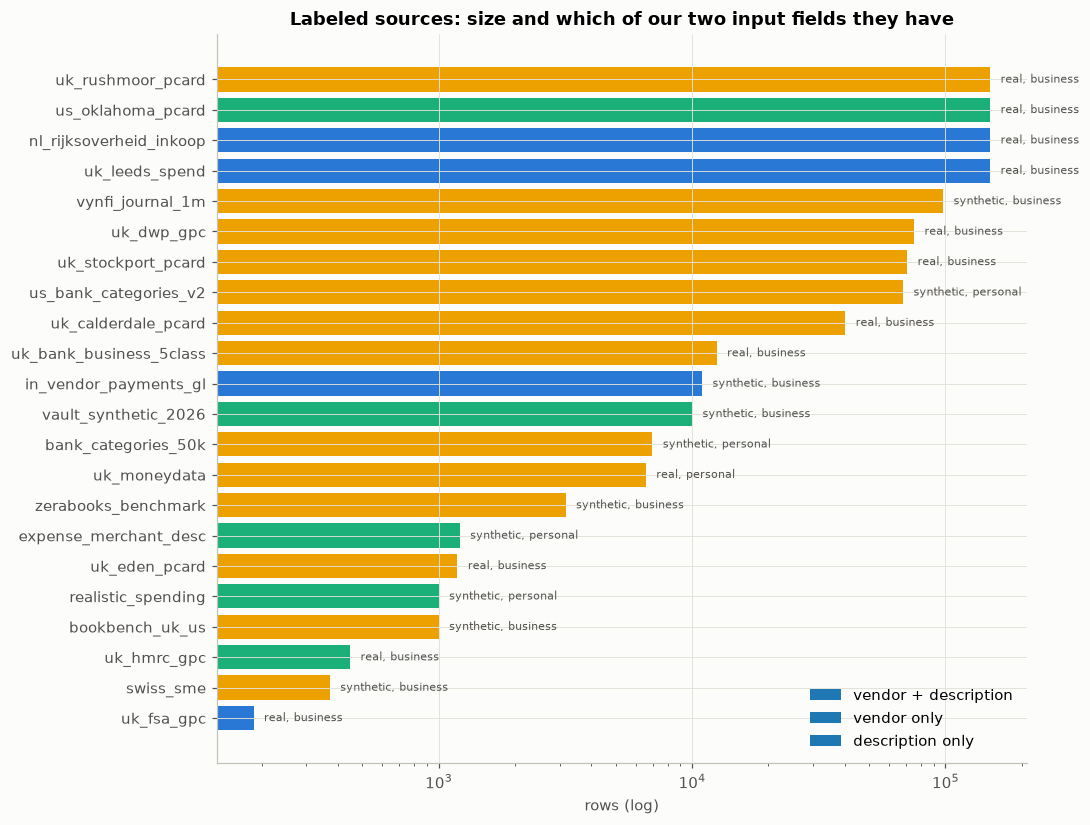

In [8]:
s = summary.sort_values('rows')
fig, ax = plt.subplots(figsize=(10, 0.3*len(s)+1))
fit = np.where((s.vendor>0.5)&(s.description>0.5),'vendor + description',np.where(s.vendor>0.5,'vendor only','description only'))
cmap = {'vendor + description':PAL[2],'vendor only':PAL[0],'description only':PAL[3]}
ax.barh(s.index, s.rows, color=[cmap[f] for f in fit]); ax.set_xscale('log')
for k,c in cmap.items(): ax.barh([],[],color=c,label=k)
for i,(r,o,k) in enumerate(zip(s.rows,s.origin,s.kind)): ax.text(r*1.1,i,f'{o}, {k}',va='center',fontsize=7,color='#52514e')
ax.legend(frameon=False, loc='lower right'); ax.set_xlabel('rows (log)'); ax.set_title('Labeled sources: size and which of our two input fields they have')
plt.tight_layout(); plt.show()

**Reading this chart:** almost no public source has *both* a vendor and a free-text description like our documents do. UK public-sector card data has vendor names and a category. Bank/journal sets have only one text line (the bank narrative, where the merchant is inside the description). So combining needs a decision on how to fill the missing field (section 7).

## 4. Distance from our data

In [9]:
def nl_share(t):
    w = set('de het een en van voor met op aan factuur btw incasso betaling termijn huur abonnement kosten'.split())
    toks = re.findall(r'[a-z]+', t.lower()); return np.mean([x in w for x in toks]) if toks else 0
smp = ds.cap_per_source(df, 3000)
smp['text'] = (smp.vendor+' '+smp.description).str.strip(); smp['len'] = smp.text.str.split().str.len()
smp['dutch'] = smp.text.map(nl_share) > 0.15
def toks(series): return set(t for x in series for t in re.findall(r'[a-z]{3,}', x.lower()))
ours = toks(smp[smp.source=='vault_synthetic_2026'].text)
gap = smp.groupby('source').agg(median_words=('len','median'), dutch=('dutch','mean'))
gap['vocab_overlap_with_ours'] = [len(toks(smp[smp.source==s].text) & ours)/max(1,len(toks(smp[smp.source==s].text))) for s in gap.index]
gap.sort_values('vocab_overlap_with_ours', ascending=False).round(2)

,median_words,dutch,vocab_overlap_with_ours
source,,,
vault_synthetic_2026,8.0,0.36,1.00
realistic_spending,4.0,0.00,0.39
swiss_sme,4.0,0.00,0.36
vynfi_journal_1m,2.0,0.00,0.30
expense_merchant_desc,3.0,0.00,0.25
uk_bank_business_5class,4.0,0.00,0.22
uk_rushmoor_pcard,0.0,0.00,0.18
uk_hmrc_gpc,4.0,0.00,0.18
uk_fsa_gpc,2.0,0.00,0.16


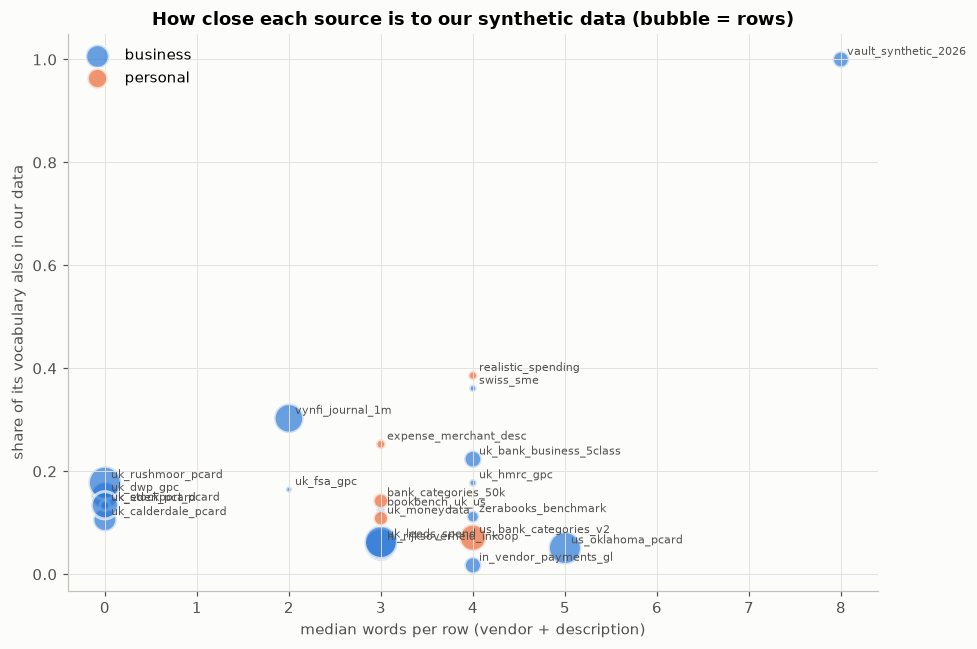

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
for kind, c in (('business',PAL[0]),('personal',PAL[1])):
    sub = gap.join(summary[['kind','rows']])[lambda x: x.kind==kind]
    ax.scatter(sub.median_words, sub.vocab_overlap_with_ours, s=np.sqrt(sub.rows)*1.2, color=c, alpha=0.7, label=kind, edgecolor='#fcfcfb', linewidth=2)
    for n,r in sub.iterrows(): ax.annotate(n, (r.median_words, r.vocab_overlap_with_ours), fontsize=7, color='#52514e', xytext=(4,3), textcoords='offset points')
ax.set_xlabel('median words per row (vendor + description)'); ax.set_ylabel('share of its vocabulary also in our data')
ax.set_title('How close each source is to our synthetic data (bubble = rows)'); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 5. Category mapping onto our 7 accounts

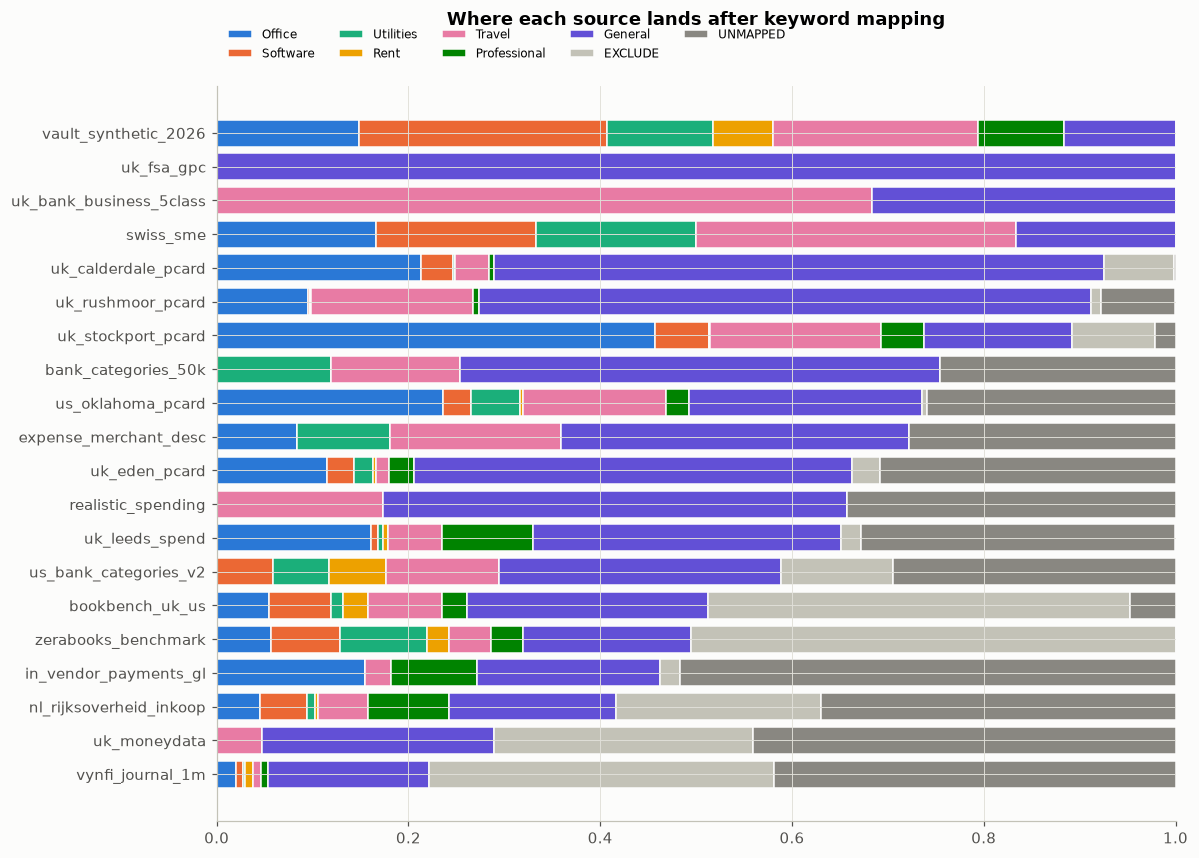

In [11]:
lab = df[df.has_label]
share = pd.crosstab(lab.source, lab.account, normalize='index')
cols = [c for c in ds.ACCOUNTS+['EXCLUDE','UNMAPPED'] if c in share]
share = share[cols].loc[share[ds.ACCOUNTS[:1] and [c for c in ds.ACCOUNTS if c in share]].sum(1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 0.32*len(share)+1.5)); left = np.zeros(len(share))
for c in cols:
    ax.barh(share.index, share[c], left=left, color=ACC_COLOR[c], label=ds.SHORT.get(c,c), edgecolor='#fcfcfb', linewidth=1); left += share[c].values
ax.set_xlim(0,1); ax.legend(ncol=5, frameon=False, bbox_to_anchor=(0,1.02,1,0.2), loc='lower left', fontsize=8)
ax.set_title('Where each source lands after keyword mapping', pad=40); plt.tight_layout(); plt.show()

In [12]:
# The labels that matter most and are still UNMAPPED: extend the rules in data_sources._RULES
lab[lab.account=='UNMAPPED'].groupby(['source','label_raw']).size().sort_values(ascending=False).head(25)

source                   label_raw                                                   
nl_rijksoverheid_inkoop  Gebruik en onderhoud gebouw en terreinen                        9292
uk_leeds_spend           Agency Staff                                                    8540
nl_rijksoverheid_inkoop  EZ specifiek                                                    7550
us_oklahoma_pcard        BOOK STORES                                                     7406
                         DENTAL/LABORATORY/MEDICAL/OPHTHALMIC HOSP EQIP AND SUP.         6855
nl_rijksoverheid_inkoop  V&J specifiek                                                   6525
uk_leeds_spend           Home Care                                                       5693
nl_rijksoverheid_inkoop  I&M specifiek                                                   4987
                         DEF specifiek                                                   4891
us_oklahoma_pcard        HOME SUPPLY WAREHOUSE STORES               

In [13]:
# Spot-check the mapping: top raw labels per account
lab[lab.account.isin(ds.ACCOUNTS)].groupby(['account','label_raw']).size().groupby(level=0, group_keys=False).nlargest(6)

account                           label_raw                                              
General/Other Expense             Studie en opleiding                                        16402
                                  Other Hired and Contracted Services                        10397
                                  Food & Drink                                                7680
                                  Services                                                    5817
                                  GROCERY STORES,AND SUPERMARKETS                             5798
                                  Groceries                                                   4645
Office Supplies Expense           STATIONERY, OFFICE SUPPLIES, PRINTING AND WRITING PAPER     8367
                                  Operational Materials                                       8219
                                  INDUSTRIAL SUPPLIES NOT ELSEWHERE CLASSIFIED                7397
                   

## 6. Experiments: does public data help?

Same model as the app's TF-IDF fusion stage (two TF-IDF vectorizers, concatenated, logistic regression). Each external row is mapped to our accounts and EXCLUDE/UNMAPPED rows are dropped.

**Test sets:**
- **synthetic test**: our vendor-disjoint test split
- **external real test**: 20% of the real business sources, split so no vendor appears in both train and test
- **ZeraBooks**: small-business bank lines from a public benchmark, never trained on (closest proxy to a customer)

**Variants:** A) synthetic only - B) + real business public data - C) B with external rows down-weighted to 0.3 - D) B + text normalization - E) B + personal-finance data - F) public data only.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from scipy.sparse import hstack
from vaultledger.normalize import normalize_counterparty, normalize_description

def fit_eval(train, tests, weight=None, norm=False):
    f = (lambda s: s.map(normalize_counterparty)) if norm else (lambda s: s.str.lower())
    g = (lambda s: s.map(normalize_description)) if norm else (lambda s: s.str.lower())
    vv, dv = TfidfVectorizer(min_df=1, max_features=60000), TfidfVectorizer(min_df=1, max_features=60000)
    X = hstack([vv.fit_transform(f(train.vendor)), dv.fit_transform(g(train.description))]).tocsr()
    m = LogisticRegression(max_iter=600, C=4).fit(X, train.account, sample_weight=weight)
    out = {}
    for name, t in tests.items():
        p = m.predict(hstack([vv.transform(f(t.vendor)), dv.transform(g(t.description))]))
        out[name+' acc'] = accuracy_score(t.account, p); out[name+' F1'] = f1_score(t.account, p, average='macro')
    return out

syn = df[df.source=='vault_synthetic_2026'].copy(); syn['account'] = syn.label_raw
syn_tr, syn_te = syn[syn.split!='test'], syn[syn.split=='test']
ok = df.account.isin(ds.ACCOUNTS) & (df.source!='vault_synthetic_2026')
real_bus = df[ok & (df.kind=='business') & (df.origin=='real')]
real_bus = ds.cap_per_source(real_bus, 25000)
gss = GroupShuffleSplit(1, test_size=0.2, random_state=0)
tr_i, te_i = next(gss.split(real_bus, groups=real_bus.vendor.str.lower().replace('', 'novendor')))
ext_tr, ext_te = real_bus.iloc[tr_i], real_bus.iloc[te_i]
zera = df[(df.source=='zerabooks_benchmark') & df.account.isin(ds.ACCOUNTS)]
other_bus = df[ok & (df.kind=='business') & (df.origin!='real') & (df.source!='zerabooks_benchmark')]
other_bus = ds.cap_per_source(other_bus, 10000)
personal = ds.cap_per_source(df[ok & (df.kind=='personal')], 8000)
tests = {'synthetic test': syn_te, 'external real test': ext_te, 'ZeraBooks': zera}
print({k: len(v) for k,v in dict(syn_tr=syn_tr, ext_tr=ext_tr, other_synth_bus=other_bus, personal=personal, **tests).items()})

{'syn_tr': 8489, 'ext_tr': 106529, 'other_synth_bus': 15944, 'personal': 16685, 'synthetic test': 1511, 'external real test': 25863, 'ZeraBooks': 1568}


In [15]:
B = pd.concat([syn_tr, ext_tr, other_bus])
w = np.where(B.source=='vault_synthetic_2026', 1.0, 0.3)
variants = {
    'A synthetic only': dict(train=syn_tr),
    'B + public business': dict(train=B),
    'C + public, weight 0.3': dict(train=B, weight=w),
    'D + public, normalized text': dict(train=B, norm=True),
    'E + personal finance': dict(train=pd.concat([B, personal])),
    'F public only': dict(train=pd.concat([ext_tr, other_bus])),
}
res = pd.DataFrame({k: fit_eval(tests=tests, **v) for k, v in variants.items()}).T
res.style.format('{:.2f}').background_gradient(cmap='Blues', vmin=0, vmax=1)

,synthetic test acc,synthetic test F1,external real test acc,external real test F1,ZeraBooks acc,ZeraBooks F1
A synthetic only,0.61,0.54,0.22,0.14,0.24,0.14
B + public business,0.63,0.55,0.57,0.45,0.43,0.30
"C + public, weight 0.3",0.65,0.59,0.58,0.45,0.38,0.24
"D + public, normalized text",0.62,0.52,0.57,0.46,0.42,0.29
E + personal finance,0.60,0.52,0.58,0.46,0.59,0.41
F public only,0.37,0.27,0.58,0.46,0.44,0.31


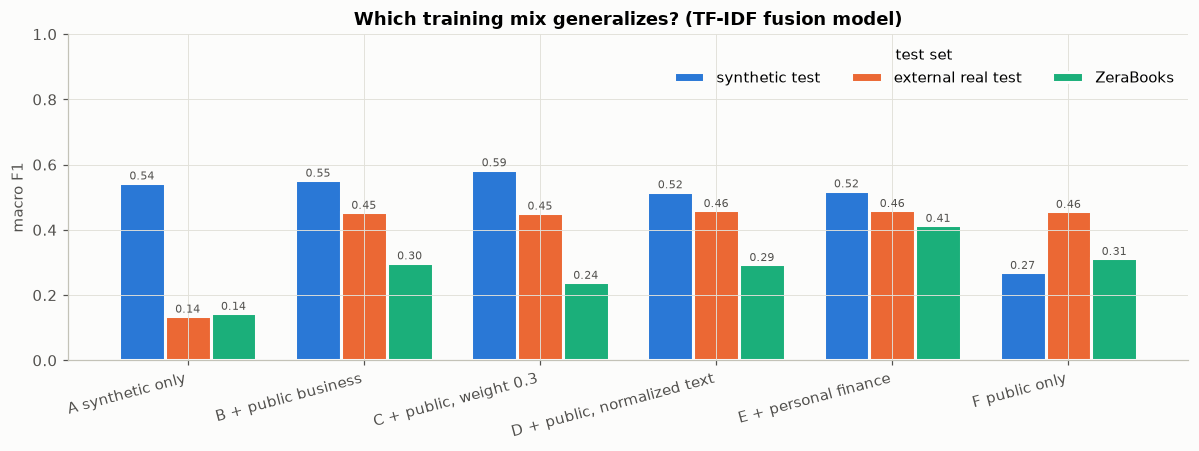

In [16]:
metric = [c for c in res.columns if c.endswith('F1')]
fig, ax = plt.subplots(figsize=(11, 4.2)); x = np.arange(len(res)); wdt = 0.26
for i, c in enumerate(metric):
    ax.bar(x+(i-1)*wdt, res[c], wdt, color=PAL[i], label=c.replace(' F1',''), edgecolor='#fcfcfb', linewidth=2)
    for xi, v in zip(x, res[c]): ax.text(xi+(i-1)*wdt, v+0.01, f'{v:.2f}', ha='center', fontsize=7, color='#52514e')
ax.set_xticks(x, res.index, rotation=15, ha='right'); ax.set_ylim(0,1); ax.set_ylabel('macro F1')
ax.legend(frameon=False, ncol=3, title='test set'); ax.set_title('Which training mix generalizes? (TF-IDF fusion model)')
plt.tight_layout(); plt.show()

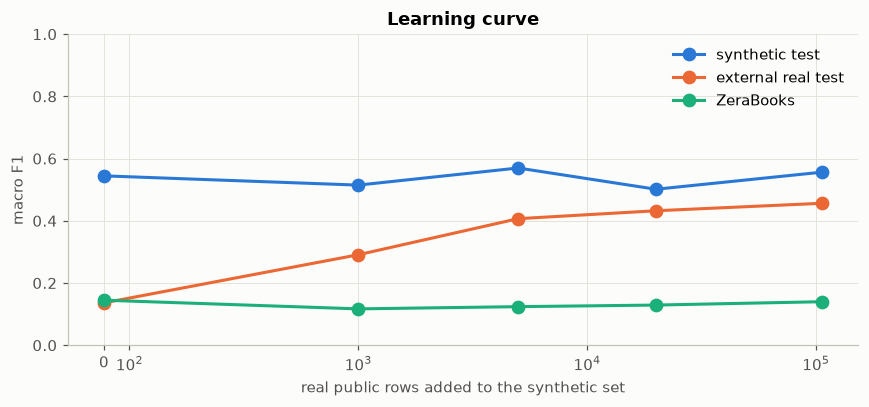

,synthetic test acc,synthetic test F1,external real test acc,external real test F1,ZeraBooks acc,ZeraBooks F1
n,,,,,,
0,0.61,0.54,0.22,0.14,0.24,0.14
1000,0.59,0.51,0.50,0.29,0.32,0.12
5000,0.62,0.57,0.57,0.41,0.33,0.12
20000,0.58,0.50,0.56,0.43,0.33,0.13
106529,0.63,0.56,0.58,0.46,0.35,0.14


In [17]:
# Learning curve: how much public data before it pays off?
curve = []
for n in [0, 1000, 5000, 20000, len(ext_tr)]:
    tr = pd.concat([syn_tr, ext_tr.sample(n, random_state=0)]) if n else syn_tr
    r = fit_eval(tr, tests); r['n'] = n; curve.append(r)
curve = pd.DataFrame(curve).set_index('n')
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, c in enumerate(metric): ax.plot(curve.index, curve[c], marker='o', ms=8, lw=2, color=PAL[i], label=c.replace(' F1',''))
ax.set_xscale('symlog', linthresh=1000); ax.set_xlabel('real public rows added to the synthetic set'); ax.set_ylabel('macro F1'); ax.set_ylim(0,1)
ax.legend(frameon=False); ax.set_title('Learning curve'); plt.tight_layout(); plt.show(); curve.round(2)

## 7. Decision guide: data manipulations

| Manipulation | What it does | When to use it | Check in this notebook |
|---|---|---|---|
| **Label mapping** (`map_to_account`) | turns each source's categories into our 7 accounts, drops non-expenses | always; it's what lets us merge sources | section 5: UNMAPPED share and spot-checks |
| **Vendor-disjoint splits** | no vendor in both train and test | always; otherwise scores are inflated by memorised vendors | section 6 |
| **Source weighting** | external rows count less than our own | when public data drowns our Dutch-specific patterns | variant C vs B |
| **Text normalization** | strips refs, store numbers, processor prefixes (`vaultledger.normalize`) | bank narratives and card data with noisy merchant strings | variant D vs B |
| **Missing field filling** | sources with vendor only -> empty description, or bank narrative -> split merchant out into vendor | needed because public data rarely has both fields | section 3 chart |
| **Dedup / template filtering** | drop near-duplicate templated rows (the Indian narration sets) | before any training; templated sets inflate accuracy | `gap` table: very low word variety |
| **Exclude personal finance** | personal categories (groceries, healthcare) don't match a company chart | default; keep only if variant E helps | variant E vs B |
| **Vendor lexicon** | use NL Rijksoverheid suppliers, OSM brand index and MCC lists as vendor -> account hints (memory / rules), not as model rows | Dutch vendor coverage; we have no Dutch line-level data | `nl_rijksoverheid_inkoop` rows |
| **DragoNet pre-training** | train DragoNet on mapped public data first, then fine-tune on synthetic + customer data | if variant B/F beats A on external and ZeraBooks tests | run `vaultledger.model.train --data` on the exported mix below |

The cell below saves the training mix chosen above so DragoNet can be trained on it.

In [18]:
out = REPO/'data'/'external'/'combined'; out.mkdir(exist_ok=True)
cols = ['vendor','description','amount','account','source','kind','origin','licence']
pd.concat([syn_tr, ext_tr, other_bus])[cols].to_csv(out/'train_mix_B.csv', index=False)
ext_te[cols].to_csv(out/'test_external_real.csv', index=False); zera[cols].to_csv(out/'test_zerabooks.csv', index=False)
print('saved to', out)

saved to C:\Users\SID-DRW\Desktop\allrepos\vault-ledger\data\external\combined
